In [1]:
import networkx as nx
G = nx.read_graphml("/home/viniz0r/Documentos/IT/Anomalias-Clim-ticas-GNN/001.graphml")

def graph_info(G):
    return f"Grafo com {G.number_of_nodes()} nós e {G.number_of_edges()} arestas. Direcionado: {G.is_directed()}"

print(graph_info(G))

Grafo com 35 nós e 86 arestas. Direcionado: False


In [2]:
def dms_to_decimal(degrees,minutes,seconds,direction):
    """
    Converte coordenadas sexagesimais (GMS) para graus decimais.

    Cálculo:
    O valor decimal é a soma dos graus inteiros, dos minutos divididos por 60 
    e dos segundos divididos por 3600. Se a direção for Sul (S) ou Oeste (W/O), 
    o valor final é convertido para negativo.

    Argumentos:
        degrees (int/float): Graus inteiros.
        minutes (int/float): Minutos (1/60 de um grau).
        seconds (int/float): Segundos (1/3600 de um grau).
        direction (str): Rosa dos ventos ('N', 'S', 'E', 'W' ou 'O').

    Retorno:
        float: Coordenada em formato decimal (ex: -23.5461).
    """
    decimal = degrees + minutes / 60 + seconds / 3600
    if direction in ['S', 'W', 'O']:
        decimal *= -1
    return decimal

coordenadas = {
 #  '0': (23, 26, 38, 'S', 46, 55, 4, 'W'), #Santana do Parnaiba
    '1': (23, 28, 46, 'S', 46, 43, 50, 'W'), #Pirituba
    '2': (23, 29, 13, 'S', 46, 41, 38, 'W'), #freguesia do ó
    '3': (23, 28, 38, 'S', 46, 36, 26, 'W'), #Tucuruvi
    '4': (23, 30, 33, 'S', 46, 36, 26, 'W'), #Vila maria / guilherme
    '5': (23, 31, 16, 'S', 46, 31, 24, 'W'), # Penha
    '6': (23, 30, 10, 'S', 46, 26, 21, 'W'), #São miguel paulista
    '7': (23, 30, 12, 'S', 46, 23, 10, 'W'), # Itaim Paulista
    '8': (23, 32, 6, 'S', 46, 27, 16, 'W'), #itaquera
    '9': (23, 36, 0, 'S', 46, 28, 50, 'W'), #São Mateus
    '10': (23, 40, 4, 'S', 46, 27, 39, 'W'), # Mauá
    '11': (23, 46, 44, 'S', 46, 31, 42, 'W'), # Riacho grande
    '12': (23, 56, 11, 'S', 46, 42, 31, 'W'), #Marsilac Palheiros
    '13': (23, 40, 58, 'S', 46, 42, 41, 'W'), # Capela do Socorro
    '14': (23, 35, 16, 'S', 46, 43, 0, 'W'), #Capela do Socorro Subprefeitura
    '15': (23, 41, 19, 'S', 46, 46, 14, 'W'), # M Boi Mirim
    '16': (23, 37, 58, 'S', 46, 45, 58, 'W'), #Campo Limpo
    '17': (23, 31, 28, 'S', 46, 42, 21, 'W'), # Lapa
    '18': (23, 33, 57, 'S', 46, 41, 22, 'W'), # Pinheiros
    '19': (23, 32, 46, 'S', 46, 37, 55, 'W'), # Sé
    '20': (23, 33, 46, 'S', 46, 35, 52, 'W'), #Mooca
    '21': (23, 34, 7, 'S', 46, 32, 49, 'W'), # Vila Formosa
    '22': (23, 35, 33,'S', 46, 34, 26, 'W'), # Vila Prudente
    '23': (23, 35, 18, 'S', 46, 38, 4, 'W'),# Vila Mariana
    '24': (23, 35, 20, 'S', 46, 36, 19, 'W'), # Ipiranga
    '25': (23, 39, 8, 'S', 46, 38, 51,'W'), #Jabaquara
    '27': (23, 24, 35, 'S', 46, 44, 34, 'W'), #Perus
    '28': (23, 49, 31,'S', 46,42,20, 'W'), #Barragem Palheiros
    '29': (23, 40, 30, 'S', 46, 39, 17, 'W'), #Cidade Ademar
    '30': (23, 34, 8, 'S', 46,43,45, 'W'), #Butantã
    '31': (23, 38, 33,'S', 46,41,58, 'W'), # Santo Amaro
    '32': (23, 24, 44, 'S', 46,35,14, 'W'), # Tremembé
    '34': (23, 29, 46, 'S', 46,37,11, 'W'),#Inmet
    '35': (23, 29, 46, 'S', 46,37,11, 'W') #Inmet convencional
}
coordenadas_decimais = {
    '33': (-23.559765113146554, -46.73399418127595), #USP
    '0': (-23.43640996621655, -46.90925768439525) #Santana do Parnaiba
}


#Adiciona os DMS - Cada entrada no dicionário contém uma tupla com oito elementos, o laço for contém dois blocos, um para latitude
#E outro para longitude, utilizando as diferentes entradas para cada.
for node_id, (dlat, mlat, slat, dir_lat, dlon, mlon, slon, dir_lon) in coordenadas.items():
    G.nodes[node_id]['lat'] = dms_to_decimal(dlat, mlat, slat, dir_lat)
    G.nodes[node_id]['lon'] = dms_to_decimal(dlon, mlon, slon, dir_lon)

# adiciona os decimais
for node_id, (lat, lon) in coordenadas_decimais.items():
    G.nodes[node_id]['lat'] = lat
    G.nodes[node_id]['lon'] = lon


In [3]:
import math

def haversine(lat1, lon1, lat2, lon2):
    """
    Calcula a distância entre dois pontos em km usando a fórmula de Haversine
    """
    R = 6371  # Raio da Terra em km

    # Converter para radianos
    lat1, lon1, lat2, lon2 = map(math.radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = math.sin(dlat/2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon/2)**2
    c = 2 * math.asin(math.sqrt(a))

    return R * c

# Verificar o tipo de grafo
print(f"Tipo de grafo: {type(G)}")
print(f"É multigrafo: {G.is_multigraph()}")

# Dicionário para armazenar os pesos
pesos = {}

# Calcular distâncias para todas as arestas
# Para multigrafos, iterar com keys=True
for u, v, key in G.edges(keys=True):
    # Verificar se ambos os nós têm coordenadas
    if 'lat' in G.nodes[u] and 'lon' in G.nodes[u] and \
       'lat' in G.nodes[v] and 'lon' in G.nodes[v]:

        lat1 = G.nodes[u]['lat']
        lon1 = G.nodes[u]['lon']
        lat2 = G.nodes[v]['lat']
        lon2 = G.nodes[v]['lon']

        # Calcular distância
        distancia = haversine(lat1, lon1, lat2, lon2)
        pesos[(u, v, key)] = distancia

        print(f"Aresta {u}-{v} (key={key}): {distancia:.2f} km")
    else:
        print(f"Aviso: Nó {u} ou {v} não tem coordenadas definidas")

# Atribuir todos os pesos de uma vez
nx.set_edge_attributes(G, pesos, 'weight')

print(f"\nTotal de arestas com peso atribuído: {len(pesos)}")

Tipo de grafo: <class 'networkx.classes.multigraph.MultiGraph'>
É multigrafo: True
Aresta 0-1 (key=2): 18.85 km
Aresta 0-17 (key=60): 22.94 km
Aresta 0-27 (key=62): 17.24 km
Aresta 1-2 (key=3): 3.83 km
Aresta 1-17 (key=25): 5.60 km
Aresta 1-27 (key=61): 7.85 km
Aresta 2-3 (key=4): 8.90 km
Aresta 2-17 (key=24): 4.34 km
Aresta 2-18 (key=32): 8.78 km
Aresta 2-32 (key=76): 13.69 km
Aresta 2-34 (key=85): 7.63 km
Aresta 2-35 (key=94): 7.63 km
Aresta 3-4 (key=5): 3.55 km
Aresta 3-18 (key=33): 12.94 km
Aresta 3-19 (key=37): 8.06 km
Aresta 3-32 (key=77): 7.51 km
Aresta 3-34 (key=83): 2.46 km
Aresta 3-35 (key=95): 2.46 km
Aresta 4-5 (key=6): 8.66 km
Aresta 4-19 (key=38): 4.82 km
Aresta 4-20 (key=49): 6.04 km
Aresta 4-32 (key=78): 10.97 km
Aresta 4-34 (key=86): 1.93 km
Aresta 4-35 (key=93): 1.93 km
Aresta 5-6 (key=7): 8.82 km
Aresta 5-20 (key=50): 8.89 km
Aresta 5-8 (key=52): 7.19 km
Aresta 5-21 (key=53): 5.80 km
Aresta 6-7 (key=8): 5.41 km
Aresta 7-8 (key=9): 7.81 km
Aresta 8-9 (key=10): 7.70 km

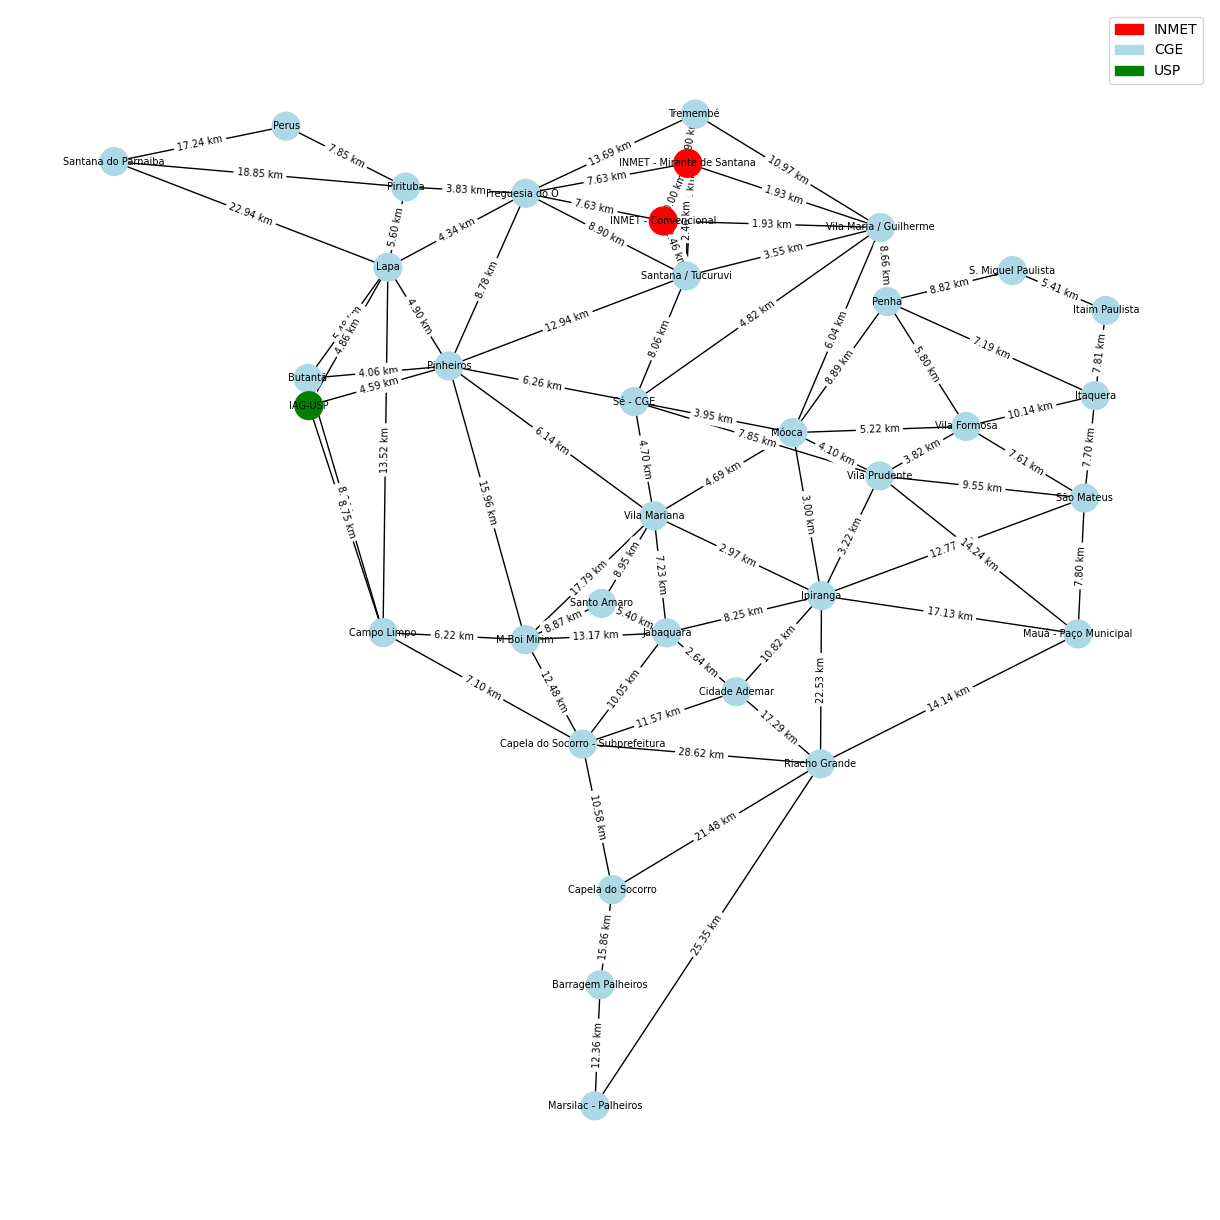

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches # <--- IMPORTANTE: Importar patches
import networkx as nx

pos = {n: (float(G.nodes[n]['x']), float(G.nodes[n]['y'])) for n in G.nodes}

edge_labels = {}
for u, v, key in G.edges(keys=True):
    if 'lat' in G.nodes[u] and 'lon' in G.nodes[u] and \
       'lat' in G.nodes[v] and 'lon' in G.nodes[v]:
        lat1, lon1 = G.nodes[u]['lat'], G.nodes[u]['lon']
        lat2, lon2 = G.nodes[v]['lat'], G.nodes[v]['lon']
        # Assumindo haversine definida
        distancia = haversine(lat1, lon1, lat2, lon2) 
        edge_labels[(u, v)] = f'{distancia:.2f} km'

# --- DEFINIÇÃO DE CORES ---
cores_dos_nos = []

for n in G.nodes:
    nome_estacao = G.nodes[n]['label'] 
    
    if 'INMET' in nome_estacao: #inmet qualquer
        cores_dos_nos.append('red')
    elif 'USP' in nome_estacao: #usp
        cores_dos_nos.append('green')
    else:   
        cores_dos_nos.append('lightblue') #cge

# --- PLOTAGEM ---
plt.figure(figsize=(12, 12))

nx.draw(
    G,
    pos,
    with_labels=True,
    labels={n: G.nodes[n]['label'] for n in G.nodes},
    node_size=400,
    node_color=cores_dos_nos,
    font_size=7,
    edge_color="black"
)

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7,
    font_color='black'
)

# Criamos manualmente os elementos da legenda (cor + texto)
legenda_inmet = mpatches.Patch(color='red', label='INMET')
legenda_cge   = mpatches.Patch(color='lightblue', label='CGE')
legenda_usp   = mpatches.Patch(color='green', label='USP')

# Adicionamos a legenda ao plot
plt.legend(handles=[legenda_inmet, legenda_cge, legenda_usp], loc='best')

plt.axis('off')
plt.show()

# Primeiro modelo GNN

#### • O treinamento foi feito com as estações de 2024 do cge, para iniciarmos de forma simples. foi feita a formatação no horário para padronizar a medição das estações e a previsão delas, o intervalo é de uma em uma hora (Exemplo: todas as medições com 10:xx foram sobreescrevidas para 10h, com a sua média atualizada. assim a previsão será para 11h.)





In [5]:
import pandas as pd
import glob
import os
import torch


PATH_2023 = "/home/viniz0r/Documentos/IT/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2023/"
PATH_2024 = "/home/viniz0r/Documentos/IT/ESTAÇÕES CGE/estações_meteorológicas_31_CGESP_2016_2024/estações_meteorológicas/meteorologicas_2024/"

def _detectar_sep(caminho_csv: str) -> str:
    with open(caminho_csv, "r", encoding="utf-8", errors="ignore") as f:
        linha = f.readline()
    return ";" if linha.count(";") > linha.count(",") else ","

def carregar_estacoes_sem_agregar(path: str) -> pd.DataFrame:
    """
    Carrega todos os CSVs das estações sem 'resample' por hora.
    Ou seja: mantém cada medição exatamente no timestamp em que ocorreu.

    Depois a gente alinha tudo no pivot (união de timestamps) e preenche faltas.
    """
    arquivos = glob.glob(os.path.join(path, "*.csv"))
    estacoes_processadas = []

    print(f"Iniciando processamento de {len(arquivos)} arquivos...")

    for arq in arquivos:
        id_estacao = os.path.basename(arq).replace(".csv", "")

        sep = _detectar_sep(arq)
        df = pd.read_csv(
            arq,
            sep=sep,
            engine="python",
            encoding="utf-8",
            on_bad_lines="skip"   # ignora linhas corrompidas
        )
        # Normaliza nomes de colunas (evita bugs com espaços invisíveis)
        df.columns = [c.strip() for c in df.columns]

        # Garante coluna DATA
        if "DATA" not in df.columns:
            # alguns arquivos podem vir como 'Data' etc.
            possiveis = [c for c in df.columns if c.lower() in ("data", "datetime", "timestamp")]
            if not possiveis:
                raise ValueError(f"CSV {arq} não tem coluna DATA. Colunas: {df.columns.tolist()}")
            df = df.rename(columns={possiveis[0]: "DATA"})

        # Converter data (ajuste dayfirst se seu CSV estiver dd/mm/aaaa)
        df["DATA"] = pd.to_datetime(df["DATA"], errors="coerce", dayfirst=True)
        df = df.dropna(subset=["DATA"]).set_index("DATA").sort_index()

        # Remove duplicatas EXATAS do mesmo timestamp (mantém o 1º registro)
        df = df[~df.index.duplicated(keep="first")]

        # Converte colunas numéricas que por acaso vieram como texto (ex: '1,2')
        for col in df.columns:
            if df[col].dtype == "object":
                df[col] = (
                    df[col].astype(str)
                          .str.replace(",", ".", regex=False)
                          .str.strip()
                )
                df[col] = pd.to_numeric(df[col], errors="ignore")

        df["station_id"] = id_estacao
        estacoes_processadas.append(df)

    df_final = pd.concat(estacoes_processadas).sort_index()
    df_final.index.name = "DATA"
    return df_final

cols_features = ["PLU(mm)", "Sens. Térmica(°C)", "Umid.Rel(%)", "Vel.VT(m/s)"]

# Executa a carga dos dois anos
df_2023 = carregar_estacoes_sem_agregar(PATH_2023)
df_2024 = carregar_estacoes_sem_agregar(PATH_2024)

print(f"Total de registros 2023: {len(df_2023)}")
print(f"Total de registros 2024: {len(df_2024)}")

Iniciando processamento de 32 arquivos...
Iniciando processamento de 32 arquivos...
Total de registros 2023: 682933
Total de registros 2024: 660316


In [6]:
import numpy as np
import re
import pandas as pd
import torch

def _primeira_coluna_existente(df: pd.DataFrame, candidatos: list[str]) -> str:
    for c in candidatos:
        if c in df.columns:
            return c
    # tenta match por lower (robusto a variações pequenas)
    lower_map = {c.lower(): c for c in df.columns}
    for c in candidatos:
        if c.lower() in lower_map:
            return lower_map[c.lower()]
    raise KeyError(f"Nenhuma das colunas {candidatos} existe. Colunas disponíveis: {df.columns.tolist()}")

def preparar_dataset_final_v4(df_input: pd.DataFrame, G):
    """
    Constrói um tensor X no formato [tempo, nós, atributos] usando TODOS os timestamps (minuto a minuto / irregular).
    1) Mapeia station_id -> node_id do grafo
    2) Faz pivot para ficar [tempo x (feature,node)]
    3) Reindexa para garantir todos os nós
    4) Preenche buracos por interpolação temporal + ffill/bfill
    """
    df_fix = df_input.copy()

    # --- (1) Escolha robusta de colunas ---
    col_plu  = _primeira_coluna_existente(df_fix, ["PLU(mm)", "PLU (mm)", "PLU_mm", "plu(mm)", "Pluviosidade(mm)"])
    col_vel  = _primeira_coluna_existente(df_fix, ["Vel.VT(m/s)", "VEL(m/s)", "VEL", "Velocidade(m/s)"])
    col_temp = _primeira_coluna_existente(df_fix, ["Sens. Térmica(°C)", "Sens. Termica(°C)", "Temp(oC)", "Temp(°C)", "Temperatura(°C)"])
    # Umidade costuma vir como 'Umid.Rel(%)' / 'UMID(%)' / etc
    col_umid = None
    for cand in ["Umid.Rel(%)", "Umid Rel(%)", "Umidade(%)", "UMID(%)", "Umidade Relativa(%)"]:
        if cand in df_fix.columns or cand.lower() in [c.lower() for c in df_fix.columns]:
            col_umid = _primeira_coluna_existente(df_fix, [cand])
            break

    # --- (2) Corrige o "deslocamento" criando colunas reais e padronizadas ---
    df_fix["PLU_real"]  = pd.to_numeric(df_fix[col_plu],  errors="coerce").fillna(0)
    df_fix["VEL_real"]  = pd.to_numeric(df_fix[col_vel],  errors="coerce").fillna(0)
    df_fix["TEMP_real"] = pd.to_numeric(df_fix[col_temp], errors="coerce")
    df_fix["TEMP_real"] = df_fix["TEMP_real"].fillna(df_fix["TEMP_real"].mean())

    if col_umid is not None:
        df_fix["UMID_real"] = pd.to_numeric(df_fix[col_umid], errors="coerce")
        df_fix["UMID_real"] = df_fix["UMID_real"].fillna(df_fix["UMID_real"].mean())
    else:
        # fallback: se não existe umidade no CSV, coloca 0 (ou você pode remover esse atributo)
        df_fix["UMID_real"] = 0.0

    # --- (3) Traduz station_id -> node_id do grafo (por label) ---
    def encontrar_no_correspondente(nome_arquivo):
        nome_arquivo = str(nome_arquivo).lower()
        for node in G.nodes():
            label = str(G.nodes[node].get("label", "")).lower()
            label_limpo = (
                label.replace(" / ", "_")
                     .replace(" ", "_")
                     .replace("ó", "o")
            )
            if label_limpo in nome_arquivo or label_limpo.split("_")[0] in nome_arquivo:
                return node
        return None

    df_fix["node_id"] = df_fix["station_id"].apply(encontrar_no_correspondente)
    df_fix = df_fix.dropna(subset=["node_id"])

    # --- (4) Pivot: índice = TODOS os timestamps (união), colunas = (feature, node) ---
    features = ["PLU_real", "TEMP_real", "UMID_real", "VEL_real"]
    nodes_lista = list(G.nodes())

    df_pivot = (
        df_fix.reset_index()
              .pivot_table(
                    index="DATA",
                    columns="node_id",
                    values=features,
                    aggfunc="mean"  # se houver 2 medições no MESMO instante para a mesma estação, tira a média
              )
              .sort_index()
    )

    # garante todas as colunas (feature,node) existentes no tensor
    df_pivot = df_pivot.reindex(
        columns=pd.MultiIndex.from_product([features, nodes_lista]),
        fill_value=np.nan
    )

    # --- (5) Preenche faltas ao longo do tempo ---
    # Interpola pelo tempo (precisa de datetime index), depois ffill/bfill e por fim zera o que sobrar
    df_pivot = df_pivot.interpolate(method="time", limit_direction="both")
    df_pivot = df_pivot.ffill().bfill().fillna(0)

    # --- (6) Converte para [Tempo, Nós, Atributos] ---
    data_3d = (
        df_pivot.values
               .reshape(len(df_pivot), len(features), len(nodes_lista))
               .transpose(0, 2, 1)
    )

    X = torch.tensor(data_3d).float().to("cuda")
    return X, df_pivot.index

# Criando X e timestamps para cada ano separadamente
X_2023, timestamps_2023 = preparar_dataset_final_v4(df_2023, G)
X_2024, timestamps_2024 = preparar_dataset_final_v4(df_2024, G)

print(f"Shape 2023: {X_2023.shape}")
print(f"Shape 2024: {X_2024.shape}")
print(f"Primeiros timestamps 2023: {list(timestamps_2023[:5])}")
print(f"Primeiros timestamps 2024: {list(timestamps_2024[:5])}")

Shape 2023: torch.Size([41706, 35, 4])
Shape 2024: torch.Size([41357, 35, 4])
Primeiros timestamps 2023: [Timestamp('2023-01-01 00:00:00'), Timestamp('2023-01-01 00:05:00'), Timestamp('2023-01-01 00:10:00'), Timestamp('2023-01-01 00:15:00'), Timestamp('2023-01-01 00:20:00')]
Primeiros timestamps 2024: [Timestamp('2024-01-01 00:00:00'), Timestamp('2024-01-01 00:05:00'), Timestamp('2024-01-01 00:10:00'), Timestamp('2024-01-01 00:15:00'), Timestamp('2024-01-01 00:20:00')]


In [7]:
# 2023 -> treino
Y_2023 = X_2023[1:, :, 0]      # chuva no próximo passo
X_2023_final = X_2023[:-1, :, :]

# 2024 -> teste
Y_2024 = X_2024[1:, :, 0]
X_2024_final = X_2024[:-1, :, :]

print(f"X_2023_final shape: {X_2023_final.shape}")
print(f"Y_2023 shape: {Y_2023.shape}")
print(f"X_2024_final shape: {X_2024_final.shape}")
print(f"Y_2024 shape: {Y_2024.shape}")

X_2023_final shape: torch.Size([41705, 35, 4])
Y_2023 shape: torch.Size([41705, 35])
X_2024_final shape: torch.Size([41356, 35, 4])
Y_2024 shape: torch.Size([41356, 35])


In [8]:
# Treino em 2023, teste em 2024
X_train, Y_train = X_2023_final, Y_2023
X_test, Y_test = X_2024_final, Y_2024

print(f"Treino (2023): {len(X_train)} amostras")
print(f"Teste  (2024): {len(X_test)} amostras")

Treino (2023): 41705 amostras
Teste  (2024): 41356 amostras


In [9]:
import dgl
import dgl.nn as dglnn
import torch.nn.functional as F

# Preparando o Grafo para a GPU via DGL
# CConvertendo o grafo do networkX "G" para DGL e movendo para CUDA
g_dgl = dgl.from_networkx(G).to('cuda')

# Criando uma camada GraphSAGE simples
# in_feats=4 (nossas variáveis), out_feats=16 (neurônios escondidos)
conv = dglnn.SAGEConv(4, 16, aggregator_type='mean').to('cuda')

# TESTE: Passar a primeira hora do ano pela GNN
# Pegamos o primeiro snapshot: X[0] -> shape [35, 4]
primeira_hora = X_train[0]
saida = conv(g_dgl, primeira_hora)

print("\n--- Teste de Processamento na GPU ---")
print(f"Entrada (35 estações, 4 atributos): {primeira_hora.shape}")
print(f"Saída após GNN (35 estações, 16 características aprendidas): {saida.shape}")

/home/viniz0r/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



--- Teste de Processamento na GPU ---
Entrada (35 estações, 4 atributos): torch.Size([35, 4])
Saída após GNN (35 estações, 16 características aprendidas): torch.Size([35, 16])


In [10]:
import torch.nn as nn
import torch.nn.functional as F
from dgl.nn import SAGEConv

class MeteorologiaGNN(nn.Module):
    def __init__(self, in_feats, h_feats):
        super(MeteorologiaGNN, self).__init__()
        # Primeira camada: recebe 4 atributos, gera 16 internos
        self.conv1 = SAGEConv(in_feats, h_feats, aggregator_type='mean')
        # Segunda camada: recebe 16 internos, gera 1 de saída (predição da chuva)
        self.conv2 = SAGEConv(h_feats, 1, aggregator_type='mean')

    def forward(self, g, in_feat):
        h = self.conv1(g, in_feat)
        h = F.relu(h) # Função de ativação para aprender padrões complexos
        h = self.conv2(g, h)
        return h.squeeze() # Remove dimensões extras (de [35, 1] para [35])

In [11]:
modelo = MeteorologiaGNN(in_feats=4, h_feats=32).to('cuda')

optimizer = torch.optim.Adam(modelo.parameters(), lr=0.001)
criterion = nn.MSELoss()

In [ ]:
from copy import deepcopy

# Instanciar o modelo
modelo = MeteorologiaGNN(in_feats=4, h_feats=32).to('cuda')
optimizer = torch.optim.Adam(modelo.parameters(), lr=0.001)
criterion = nn.MSELoss()

# Early stopping
max_epochs  = 500
target_loss = 1e-4
min_delta   = 1e-6
patience    = 2

best_loss = float("inf")
no_improve = 0
best_state = None
historico_loss = []

modelo.train()
for epoch in range(1, max_epochs + 1):
    total_loss = 0.0

    for i in range(len(X_train)):
        pred = modelo(g_dgl, X_train[i])
        loss = criterion(pred, Y_train[i])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += float(loss.item())

    epoch_loss = total_loss / len(X_train)
    historico_loss.append(epoch_loss)

    print(f"Época {epoch:4d} | Erro treino (2023): {epoch_loss:.8f}")

    if epoch_loss <= target_loss:
        print(f"Parando: erro <= {target_loss} (erro={epoch_loss:.8f}) na época {epoch}")
        best_state = deepcopy(modelo.state_dict())
        break

    if best_loss - epoch_loss > min_delta:
        best_loss = epoch_loss
        no_improve = 0
        best_state = deepcopy(modelo.state_dict())
    else:
        no_improve += 1
        if no_improve >= patience:
            print(
                f"Parando: melhora < {min_delta} por {patience} épocas seguidas. "
                f"best={best_loss:.8f}, atual={epoch_loss:.8f}, época {epoch}"
            )
            break

if best_state is not None:
    modelo.load_state_dict(best_state)

Época    1 | Erro treino (2023): 0.25951006
Época    2 | Erro treino (2023): 0.12502983


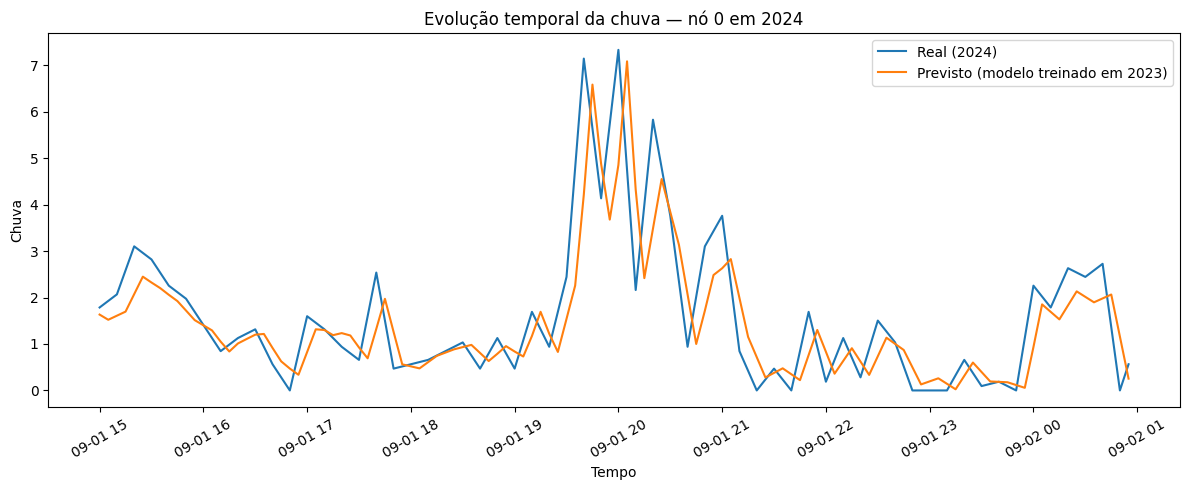

Nó 0 | MAE total em 2024 = 0.330654
Nó 0 | RMSE total em 2024 = 0.460106
Pico real em índice 27772, janela mostrada: 27712 até 27832


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

node_id = 0          # escolha a estação/nó
window = 120         # tamanho total da janela
half_window = window // 2

modelo.eval()

preds_2024 = []
trues_2024 = []

with torch.no_grad():
    for i in range(len(X_test)):
        pred = modelo(g_dgl, X_test[i])

        y_pred = pred.detach().cpu().numpy().reshape(-1)
        y_true = Y_test[i].detach().cpu().numpy().reshape(-1)

        preds_2024.append(y_pred[node_id])
        trues_2024.append(y_true[node_id])

preds_2024 = np.array(preds_2024)
trues_2024 = np.array(trues_2024)

# encontra o maior pico real
peak_idx = np.argmax(trues_2024)

# define janela ao redor do pico
start = max(0, peak_idx - half_window)
end = min(len(trues_2024), peak_idx + half_window)

# timestamps corretos do teste 2024
tempo_2024 = np.array(timestamps_2024[1:])

plt.figure(figsize=(12, 5))
plt.plot(tempo_2024[start:end], trues_2024[start:end], label="Real (2024)")
plt.plot(tempo_2024[start:end], preds_2024[start:end], label="Previsto (modelo treinado em 2023)")
plt.xlabel("Tempo")
plt.ylabel("Chuva")
plt.title(f"Evolução temporal da chuva — nó {node_id} em 2024")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

mae = np.mean(np.abs(preds_2024 - trues_2024))
rmse = np.sqrt(np.mean((preds_2024 - trues_2024) ** 2))

print(f"Nó {node_id} | MAE total em 2024 = {mae:.6f}")
print(f"Nó {node_id} | RMSE total em 2024 = {rmse:.6f}")
print(f"Pico real em índice {peak_idx}, janela mostrada: {start} até {end}")

In [ ]:
# =========================
# PREVISÃO DE TEMPERATURA
# =========================

TARGET_IDX_TEMP = 1  # TEMP_real

# 2023 -> treino
Y_2023_temp = X_2023[1:, :, TARGET_IDX_TEMP]
X_2023_temp = X_2023[:-1, :, :]

# 2024 -> teste
Y_2024_temp = X_2024[1:, :, TARGET_IDX_TEMP]
X_2024_temp = X_2024[:-1, :, :]

X_train_temp, Y_train_temp = X_2023_temp, Y_2023_temp
X_test_temp, Y_test_temp = X_2024_temp, Y_2024_temp

print(f"X_train_temp: {X_train_temp.shape}")
print(f"Y_train_temp: {Y_train_temp.shape}")
print(f"X_test_temp:  {X_test_temp.shape}")
print(f"Y_test_temp:  {Y_test_temp.shape}")

X_train_temp: torch.Size([41705, 35, 4])
Y_train_temp: torch.Size([41705, 35])
X_test_temp:  torch.Size([41356, 35, 4])
Y_test_temp:  torch.Size([41356, 35])


In [ ]:
from copy import deepcopy
import torch
import torch.nn as nn

modelo_temp = MeteorologiaGNN(in_feats=4, h_feats=32).to('cuda')
optimizer_temp = torch.optim.Adam(modelo_temp.parameters(), lr=0.001)
criterion_temp = nn.MSELoss()

max_epochs  = 30
target_loss = 1e-4
min_delta   = 1e-6
patience    = 2

best_loss_temp = float("inf")
no_improve_temp = 0
best_state_temp = None
historico_loss_temp = []

modelo_temp.train()
for epoch in range(1, max_epochs + 1):
    total_loss = 0.0

    for i in range(len(X_train_temp)):
        pred = modelo_temp(g_dgl, X_train_temp[i])
        loss = criterion_temp(pred, Y_train_temp[i])

        optimizer_temp.zero_grad()
        loss.backward()
        optimizer_temp.step()

        total_loss += float(loss.item())

    epoch_loss = total_loss / len(X_train_temp)
    historico_loss_temp.append(epoch_loss)

    print(f"Época {epoch:4d} | Erro treino temperatura (2023): {epoch_loss:.8f}")

    if epoch_loss <= target_loss:
        print(f"Parando: erro <= {target_loss} (erro={epoch_loss:.8f}) na época {epoch}")
        best_state_temp = deepcopy(modelo_temp.state_dict())
        break

    if best_loss_temp - epoch_loss > min_delta:
        best_loss_temp = epoch_loss
        no_improve_temp = 0
        best_state_temp = deepcopy(modelo_temp.state_dict())
    else:
        no_improve_temp += 1
        if no_improve_temp >= patience:
            print(
                f"Parando: melhora < {min_delta} por {patience} épocas seguidas. "
                f"best={best_loss_temp:.8f}, atual={epoch_loss:.8f}, época {epoch}"
            )
            break

if best_state_temp is not None:
    modelo_temp.load_state_dict(best_state_temp)

Época    1 | Erro treino temperatura (2023): 1.13939525
Época    2 | Erro treino temperatura (2023): 0.01356449
Época    3 | Erro treino temperatura (2023): 0.01227965
Época    4 | Erro treino temperatura (2023): 0.01109266
Época    5 | Erro treino temperatura (2023): 0.01008991
Época    6 | Erro treino temperatura (2023): 0.00952127
Época    7 | Erro treino temperatura (2023): 0.00894431
Época    8 | Erro treino temperatura (2023): 0.00838322
Época    9 | Erro treino temperatura (2023): 0.00789418
Época   10 | Erro treino temperatura (2023): 0.00726920
Época   11 | Erro treino temperatura (2023): 0.00666258
Época   12 | Erro treino temperatura (2023): 0.00611451
Época   13 | Erro treino temperatura (2023): 0.00564277
Época   14 | Erro treino temperatura (2023): 0.00520029
Época   15 | Erro treino temperatura (2023): 0.00468470
Época   16 | Erro treino temperatura (2023): 0.00400011
Época   17 | Erro treino temperatura (2023): 0.00351156
Época   18 | Erro treino temperatura (2023): 0.0

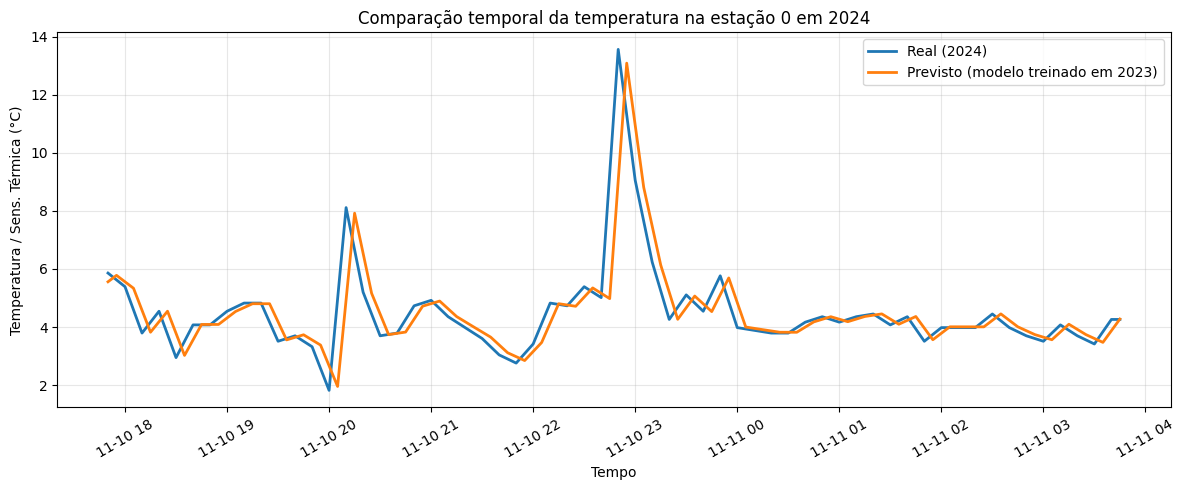

Nó 0 | MAE total temperatura em 2024 = 0.213888
Nó 0 | RMSE total temperatura em 2024 = 0.293999
Janela mostrada: 37250 até 37370


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

node_id = 0
window = 120
half_window = window // 2

modelo_temp.eval()

preds_temp_2024 = []
trues_temp_2024 = []

with torch.no_grad():
    for i in range(len(X_test_temp)):
        pred = modelo_temp(g_dgl, X_test_temp[i])

        y_pred = pred.detach().cpu().numpy().reshape(-1)
        y_true = Y_test_temp[i].detach().cpu().numpy().reshape(-1)

        preds_temp_2024.append(y_pred[node_id])
        trues_temp_2024.append(y_true[node_id])

preds_temp_2024 = np.array(preds_temp_2024)
trues_temp_2024 = np.array(trues_temp_2024)

# pega uma janela em torno do ponto de maior desvio em relação à média
peak_idx = np.argmax(np.abs(trues_temp_2024 - np.mean(trues_temp_2024)))

start = max(0, peak_idx - half_window)
end = min(len(trues_temp_2024), peak_idx + half_window)

tempo_2024 = np.array(timestamps_2024[1:])

plt.figure(figsize=(12, 5))
plt.plot(
    tempo_2024[start:end],
    trues_temp_2024[start:end],
    linewidth=2,
    label="Real (2024)"
)
plt.plot(
    tempo_2024[start:end],
    preds_temp_2024[start:end],
    linewidth=2,
    label="Previsto (modelo treinado em 2023)"
)
plt.xlabel("Tempo")
plt.ylabel("Temperatura / Sens. Térmica (°C)")
plt.title(f"Comparação temporal da temperatura na estação {node_id} em 2024")
plt.legend()
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

mae_temp = np.mean(np.abs(preds_temp_2024 - trues_temp_2024))
rmse_temp = np.sqrt(np.mean((preds_temp_2024 - trues_temp_2024) ** 2))

print(f"Nó {node_id} | MAE total temperatura em 2024 = {mae_temp:.6f}")
print(f"Nó {node_id} | RMSE total temperatura em 2024 = {rmse_temp:.6f}")
print(f"Janela mostrada: {start} até {end}")